# Write and test a custom model

**TimeGym can test any forecaster you can write as two methods.** `fit` receives the history. `predict` receives the dates to forecast and returns the forecast. That is the whole interface: no base class to inherit, nothing to register.

In this notebook we write the simplest model that works and see what TimeGym makes of it. Then we build a smarter one that searches history for moments like the present, find out where it shines and where it can't cope, break it on purpose, and finally point it at real airline data.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import timegym
from timegym import Pipeline, Scenario, Forecast, ForecastTask, Reference, Case
from timegym.contracts import DEFAULT_LEVELS
from timegym.diagnostics import evaluate_forecast
from timegym.evaluation import EvaluatedCase, ForecastRun

%matplotlib inline
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").is_file() and (p / "timegym").is_dir())
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## 1 · The simplest model that works

Here is a complete forecaster. It predicts that every future value equals the last value it saw.

- `fit(context)` gets the **history**: a pandas DataFrame with one row per past time step and one column per series. Store whatever you learn and return `self`.
- `predict(future_index)` gets **the dates to forecast**: a pandas index holding the labels of the steps right after the history.
- It returns a `Forecast`: the same dates (`index`), the predicted values (`point`, an array with one row per step and one column per series) and the series names in the same order (`target_names`). A `Forecast` can also carry quantiles or sample paths, as we'll see later.

In [2]:
class LastValue:
    def fit(self, context):            # DataFrame: one row per past step, one column per target
        self.last_ = context.iloc[-1].to_numpy()
        self.targets_ = tuple(context.columns)
        return self

    def predict(self, future_index):   # the time labels to forecast
        point = np.tile(self.last_, (len(future_index), 1))   # (steps, targets)
        return Forecast(index=future_index, point=point, target_names=self.targets_)

To see what the model receives, generate one series and call it by hand. A `Scenario` describes a kind of series; `generate(seed)` draws one example, split into the history the model sees and the future it doesn't.

In [3]:
walk = Scenario("random_walk", context_length=100, horizon=10, parameters={"drift": 0.0, "sigma": 0.5})
walk_case = walk.generate(seed=1)
history, dates_to_forecast = walk_case.task.context, walk_case.task.future_index

print("The last three rows of the history:")
display(history.tail(3))
print("The dates to forecast:", list(dates_to_forecast))
forecast = LastValue().fit(history).predict(dates_to_forecast)
print("The forecast:", forecast.point[:, 0].round(3))

The last three rows of the history:


,y
97,-3.307130
98,-4.019805
99,-3.853398


The dates to forecast: [100, 101, 102, 103, 104, 105, 106, 107, 108, 109]
The forecast: [-3.853 -3.853 -3.853 -3.853 -3.853 -3.853 -3.853 -3.853 -3.853 -3.853]


## 2 · Let TimeGym test it

`Pipeline(LastValue).test(...)` does the by-hand steps for you on every scenario and seed, with a fresh model each time, and checks every forecast. We try three kinds of series, three examples each: noise around a constant level (`white_noise`), noise around a straight line (`trend`), and a random walk, where shocks never fade.

For each forecast TimeGym knows the **answer key**: what a perfect forecaster that knows the true process would predict. That gives two errors. The *error against the answer key* measures the model. The *error against what actually happened* also includes noise that nobody could have predicted.

In [4]:
simple_suite = [
    Scenario("white_noise", context_length=100, horizon=10, parameters={"mean": 2.0, "sigma": 0.5}),
    Scenario("trend", context_length=100, horizon=10, parameters={"intercept": 0.0, "slope": 0.1, "sigma": 0.15}),
    walk,
]
last_value_report = Pipeline(LastValue).test(simple_suite, seeds=[1, 2, 3])
last_value_report.assert_passed()  # every forecast passes the output checks; nothing crashed
scores = pd.DataFrame([{"series": r.scenario,
                        "error against the answer key": r.metrics["mean_reference_mse"],
                        "error against what actually happened": r.metrics["mse"]}
                       for r in last_value_report.cases])
display(scores.groupby("series", sort=False).mean().round(3))
assert (scores.loc[scores["series"] == "random_walk", "error against the answer key"] == 0).all()

,error against the answer key,error against what actually happened
series,,
white_noise,0.069,0.367
trend,0.406,0.498
random_walk,0.000,0.728


On the random walk the simplest model has **zero** error against the answer key: it is exactly the best possible forecast. When shocks never fade, today's value is the best guess for every future step, and TimeGym confirms it. The walk still moves, so the error against what actually happened is not zero. No model can predict those shocks.

On the straight line the last value falls further behind with every step. On noise around a level it bets on one noisy point instead of the average. Same model, three verdicts: what a model is good at depends on the kind of series, and that is what TimeGym is for.

## 3 · A smarter model: nearest analogues

Now something with more to it. To forecast the next 36 steps, look at the last 12 values, find the 8 moments in history that looked most like them, and average what happened next after each one. If history repeats, this works. If it doesn't, the model has nothing to copy.

Each of the 8 continuations is a whole future path, so the model can also return them as `samples`, and their percentiles as `quantiles`. Two optional extras help the `Pipeline`: `clone_unfitted()` gives it a fresh copy for every case, and `params()` records the settings in the report.

In [5]:
from numbers import Integral


class NearestAnalogues:
    def __init__(self, *, window_length=12, k=8):
        for name, value in {"window_length": window_length, "k": k}.items():
            if isinstance(value, bool) or not isinstance(value, Integral) or value < 1:
                raise ValueError(f"{name} must be a positive integer")
        self.window_length = int(window_length)
        self.k = int(k)

    def params(self):
        return {"window_length": self.window_length, "k": self.k}

    def clone_unfitted(self):
        return type(self)(**self.params())

    def fit(self, context):
        if not isinstance(context, pd.DataFrame):
            raise TypeError("context must be a pandas DataFrame")
        self.context_ = context.copy(deep=True)
        return self

    def predict(self, future_index):
        if not hasattr(self, "context_"):
            raise RuntimeError("Call fit(context) before predict(future_index)")
        task = ForecastTask(self.context_, future_index)
        values = task.context.to_numpy(dtype=float)
        window, horizon = self.window_length, len(future_index)
        count = len(values) - window - horizon + 1
        if count < self.k:
            raise ValueError(
                f"Need at least window_length + horizon + k - 1 context rows; "
                f"got {len(values)} for window_length={window}, horizon={horizon}, k={self.k}"
            )
        windows = np.stack([values[start:start + window] for start in range(count)])
        distances = np.mean((windows - values[-window:]) ** 2, axis=(1, 2))
        self.neighbor_starts_ = np.argsort(distances, kind="stable")[:self.k]
        paths = np.stack([values[start + window:start + window + horizon]
                          for start in self.neighbor_starts_])
        return Forecast(
            index=future_index.copy(), point=paths.mean(axis=0), samples=paths,
            quantiles=np.quantile(paths, DEFAULT_LEVELS, axis=0).transpose(1, 2, 0),
            levels=DEFAULT_LEVELS, target_names=task.target_names,
        )

Try it on a repeating cycle with a period of 24 steps. Which moments did the model pick as analogues?

In [6]:
example = Scenario("seasonal", context_length=240, horizon=36,
                   parameters={"mean": 2.0, "amplitude": 1.0, "period": 24.0, "sigma": 0.15})
case = example.generate(seed=7)
model = NearestAnalogues(window_length=12, k=8).fit(case.task.context)
forecast = model.predict(case.task.future_index)

starts = np.sort(model.neighbor_starts_)
ends = starts + model.window_length + len(case.task.future_index)
assert np.all(ends <= len(case.task.context))  # every analogue's future is already in the history
print("Analogue windows start at steps", starts.tolist())
print("Where each start falls in the 24-step cycle:", (starts % 24).tolist())

Analogue windows start at steps [36, 60, 83, 84, 108, 132, 156, 180]
Where each start falls in the 24-step cycle: [12, 12, 11, 12, 12, 12, 12, 12]


Seven of the eight analogues start at exactly the same point in the 24-step cycle, and the eighth is one step off. The model found the same moment in the cycle, season after season, without being told the period. Every chosen window is followed by 36 observed steps, so the model never peeks past the end of its history.

In the plot, gray dots are the history and what actually happened, blue crosses are the forecast (the average of the 8 continuations), the band covers the middle 80% of those continuations at each step, and the thin line is the answer key.

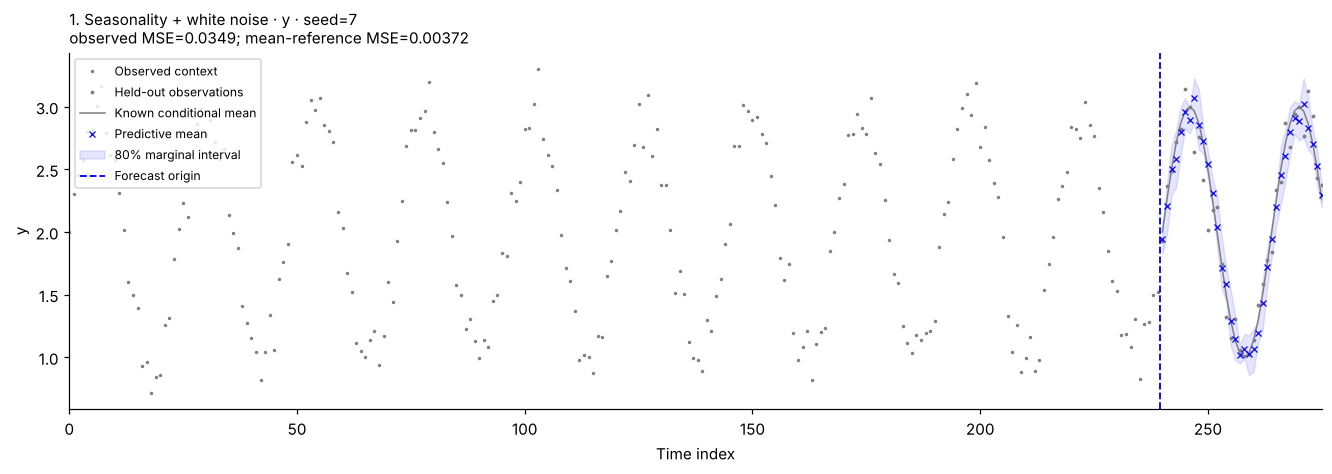

Error against the answer key: 0.0037; against what actually happened: 0.0349


In [7]:
result = evaluate_forecast(case, forecast)
example_run = ForecastRun([EvaluatedCase(case, forecast, result, 0, 0)])
fig = example_run.plot_forecasts(show_quantiles=True, figsize=(12, 4.2))
plt.show()
print(f"Error against the answer key: {result.metrics['mean_reference_mse']:.4f}; "
      f"against what actually happened: {result.metrics['mse']:.4f}")

The crosses follow the answer key closely. Most of the remaining error against what actually happened is the noise around the cycle, which no model could predict.

## 4 · Where does it shine, and where can't it cope?

Run the same three kinds of series through `Pipeline.run`, two examples each. `run` keeps the forecasts for plotting; its `.report` holds the same checks and scores as `test`. Noise around a level asks how well 8 continuations estimate a fixed mean. The straight line asks whether the model can go somewhere it has never been. The cycle asks whether the right pattern recurs in history.

In [8]:
pipeline = Pipeline(NearestAnalogues(window_length=12, k=8))
suite = [
    Scenario("white_noise", context_length=240, horizon=36,
             parameters={"mean": 2.0, "sigma": 0.5}),
    Scenario("trend", context_length=240, horizon=36,
             parameters={"intercept": 0.0, "slope": 0.02, "sigma": 0.15}),
    example,
]
seeds = [7, 19]
retained = pipeline.run(suite, seeds=seeds)
retained.report.assert_passed()  # all six forecasts pass the output checks
display(pd.DataFrame([{"series": r.scenario, "seed": r.seed,
                       "error against the answer key": r.metrics["mean_reference_mse"],
                       "error against what actually happened": r.metrics["mse"],
                       "point accuracy": next(d.status for d in r.diagnostics if d.name == "point_accuracy")}
                      for r in retained.report.cases]).round(4))

,series,seed,error against the answer key,error against what actually happened,point accuracy
0,white_noise,7,0.0325,0.3210,INCONCLUSIVE
1,white_noise,19,0.0195,0.2293,INCONCLUSIVE
2,trend,7,0.6800,0.6696,INCONCLUSIVE
3,trend,19,0.6395,0.6741,INCONCLUSIVE
4,seasonal,7,0.0037,0.0349,INCONCLUSIVE
5,seasonal,19,0.0037,0.0211,INCONCLUSIVE


Point accuracy is INCONCLUSIVE everywhere: TimeGym scored it, but we haven't said how much error is too much, and it won't invent a pass mark. The scores already tell a story, and the plot shows it.

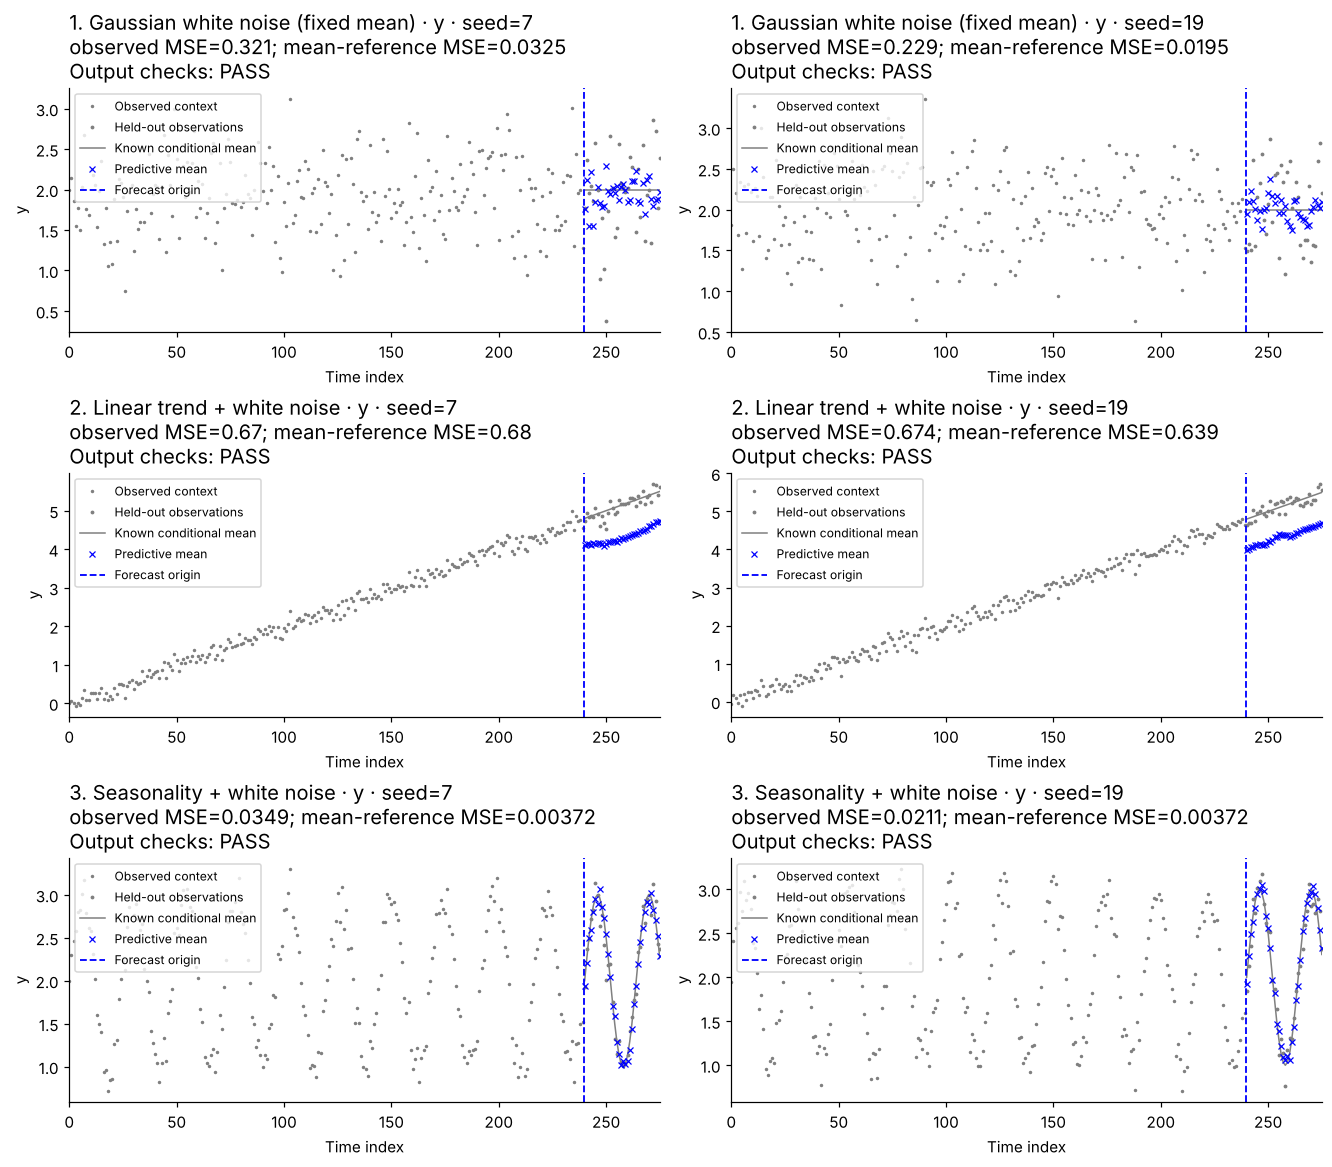

In [9]:
def plot_contracts(run, *, figsize):
    fig = run.plot_forecasts(figsize=figsize)
    for ax, entry in zip(fig.axes, run.cases):
        contract = next(d.status for d in entry.result.diagnostics
                        if d.name == "forecast_contract" or d.name.startswith("contract_"))
        ax.set_title(ax.get_title(loc="left") + f"\nOutput checks: {contract}", loc="left")
    return fig


fig = plot_contracts(retained, figsize=(12, 10.5))
asset_path = ROOT / "notebooks" / "assets" / "custom-model-knn.png"
asset_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(asset_path, dpi=150, bbox_inches="tight")
plt.show()

The straight line exposes the model's blind spot even though every output check passes. Averaging past continuations can never produce a value higher than anything in history, so on a rising line the forecast trails from the first step and falls further behind the answer key. On the cycle it does well because the pattern recurs. That is a property of this model on these series, not a ranking of forecasting methods.

## 5 · Break it on purpose

An inaccurate forecast is not a broken one. To see a real failure, inject a bug: drop the last forecast row while keeping all the requested dates. The forecast now has 35 values for 36 dates. TimeGym fails it on the output checks (`contract_point_shape`) and the plot withholds the malformed forecast instead of drawing misaligned points.

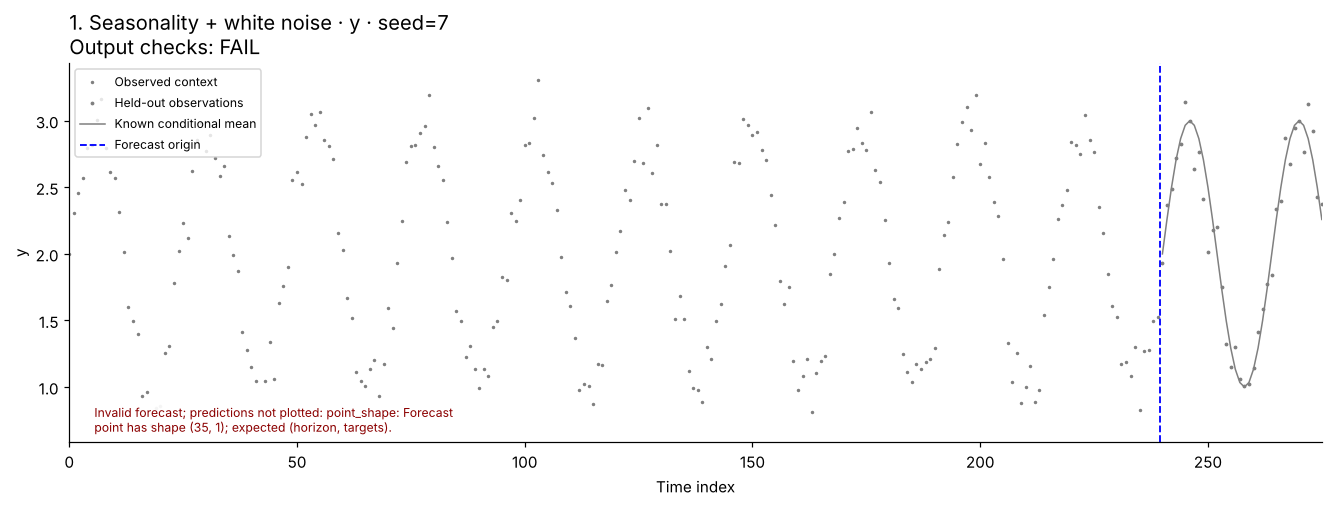

contract_point_shape: FAIL. Forecast point has shape (35, 1); expected (horizon, targets).


In [10]:
class MissingLastPoint(NearestAnalogues):
    def predict(self, future_index):
        prediction = super().predict(future_index)
        prediction.point = prediction.point[:-1]
        return prediction


broken_run = Pipeline(MissingLastPoint(window_length=12, k=8)).run([example], seeds=[7])
shape_check = broken_run.report.cases[0].diagnostics[0]
assert (shape_check.name, shape_check.status) == ("contract_point_shape", "FAIL")  # missing row fails
fig = plot_contracts(broken_run, figsize=(12, 4.5))
plt.show()
print(f"{shape_check.name}: {shape_check.status}. {shape_check.message}")

## 6 · Real data: no answer key

Synthetic series come with an answer key. Real data doesn't. Here the model forecasts the last 12 months of the classic AirPassengers series (monthly international airline passengers, in thousands, 1949 to 1960) from the 132 months before. The [data record](../experiments/data/README.md) gives its source and checksum.

We keep only the model's point forecast. TimeGym still runs the output checks and scores the forecast against what actually happened, but the checks that need an answer key or uncertainty come back **UNSUPPORTED**: not checked, because what they need isn't there. A missing score is left out, not set to zero.

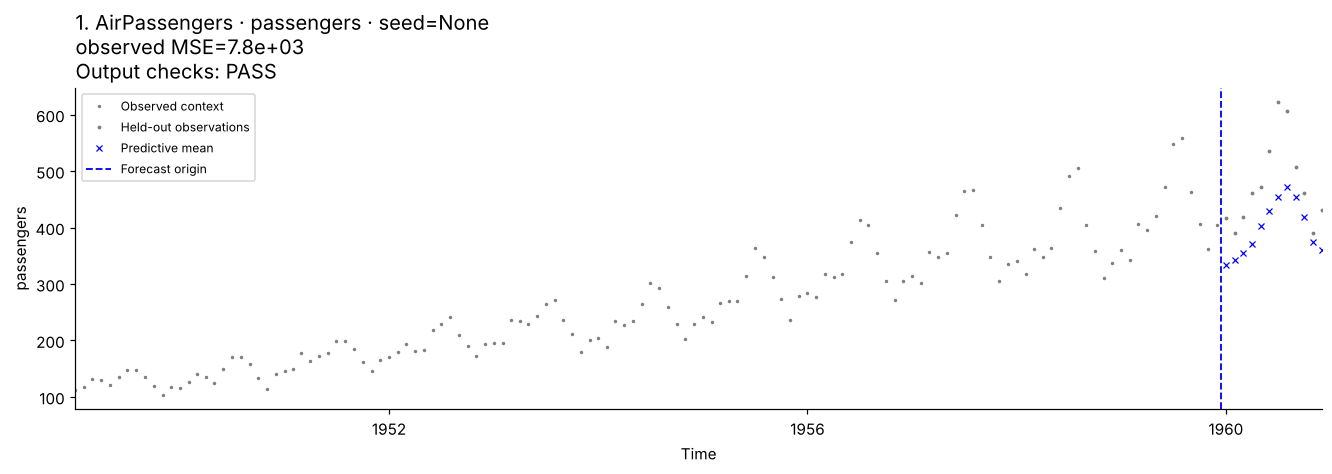

,check,status
0,forecast_contract,PASS
1,point_accuracy,INCONCLUSIVE
2,quantile_accuracy,UNSUPPORTED
3,sample_scores,UNSUPPORTED
4,reference_covariance,UNSUPPORTED


In [11]:
data_path = ROOT / "experiments" / "data" / "AirPassengers.csv"
source_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert source_sha256 == "bdb98adbd418a6de6842a742e0602f363c3b841c26677e7e61a1e055e9509bd8"  # the bundled file
raw = pd.read_csv(data_path)
series = pd.DataFrame({"passengers": raw["value"].to_numpy(dtype=float)},
                      index=pd.period_range("1949-01", periods=len(raw), freq="M"))
origin = 132
real_task = ForecastTask(series.iloc[:origin].copy(), series.index[origin:].copy())
real_case = Case(real_task, series.iloc[origin:].copy(), reference=None,
                 manifest={"kind": "AirPassengers", "seed": None,
                           "context_length": origin, "horizon": len(real_task.future_index),
                           "source_sha256": source_sha256})


def point_prediction(task):
    prediction = pipeline.predict(task.context, task.future_index)
    return Forecast(index=prediction.index, point=prediction.point,
                    target_names=prediction.target_names)


real_forecast = point_prediction(real_task)
real_result = evaluate_forecast(real_case, real_forecast, check_dependence=True)
assert "mean_reference_mse" not in real_result.metrics  # no answer key, so no such score
real_run = ForecastRun([EvaluatedCase(real_case, real_forecast, real_result, 0, 0)])
fig = plot_contracts(real_run, figsize=(12, 4.2))
plt.show()
display(pd.DataFrame([{"check": d.name, "status": d.status} for d in real_result.diagnostics]))

The model passes the output checks and undershoots badly. Airline traffic grows year on year, and, as on the straight line above, copying past continuations can't reach levels history has never seen.

### Give real data an answer key

There is a middle way between synthetic and real data: build a series whose answer key you choose, shaped like the real one. Smooth AirPassengers with a centered 3-month average and declare that curve the true mean. Then add fresh random noise (standard deviation 10) to create new observations. The model sees only the new noisy history; TimeGym knows the curve.

`Reference.from_function(truth, dates, covariance=...)` turns such a curve into an answer key. It needs the curve's values on the dates to forecast and the noise covariance, here independent noise with variance 10². The curve is the truth for this constructed series only; it says nothing about the true mean of airline demand.

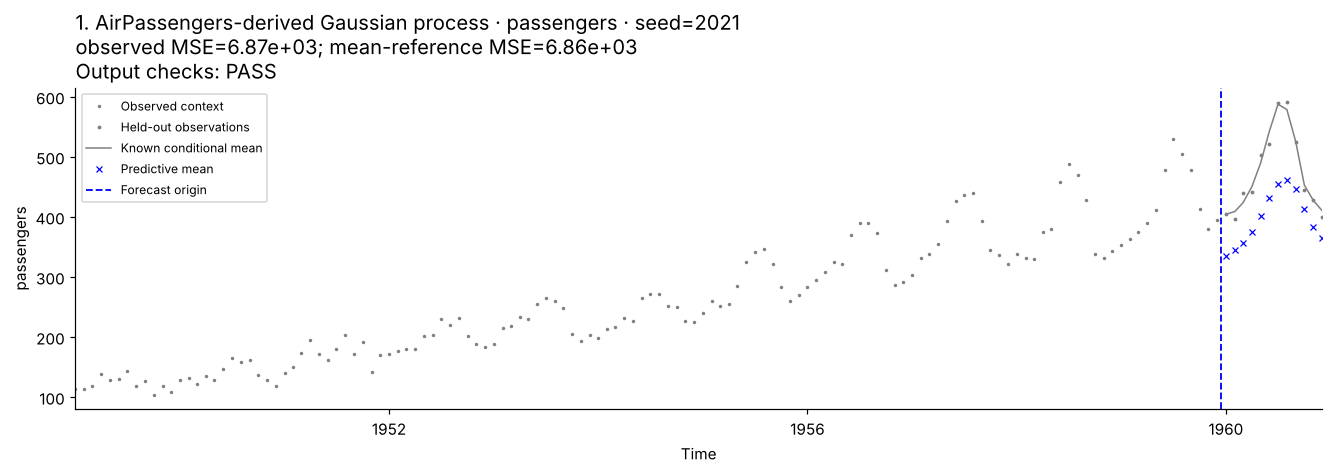

In [12]:
truth_curve = series.rolling(window=3, center=True, min_periods=1).mean()


def truth(index):
    return truth_curve.loc[index].copy()


noise_sd = 10.0
semi_seed = 2021
rng = np.random.default_rng(semi_seed)
semi_observed = truth(series.index) + rng.normal(0.0, noise_sd, size=series.shape)
semi_task = ForecastTask(semi_observed.iloc[:origin].copy(), series.index[origin:].copy())
known_reference = Reference.from_function(
    truth, semi_task.future_index,
    covariance=noise_sd**2 * np.eye(len(semi_task.future_index)),
    target_names=semi_task.target_names,
    conditioning={"source_sha256": source_sha256,
                  "truth": "fixed centered 3-month mean, min_periods=1",
                  "noise": "independent Gaussian", "noise_sd": noise_sd},
)
semi_case = Case(semi_task, semi_observed.iloc[origin:].copy(), known_reference,
                 {"kind": "AirPassengers-derived Gaussian process", "seed": semi_seed,
                  "context_length": origin, "horizon": len(semi_task.future_index),
                  "reference_kind": known_reference.kind,
                  "reference_conditioning": known_reference.conditioning})
semi_forecast = point_prediction(semi_task)
semi_result = evaluate_forecast(semi_case, semi_forecast, check_dependence=True)
np.testing.assert_allclose(known_reference.mean, truth(semi_task.future_index).to_numpy())  # the key is the curve
semi_run = ForecastRun([EvaluatedCase(semi_case, semi_forecast, semi_result, 0, 0)])
fig = plot_contracts(semi_run, figsize=(12, 4.2))
plt.show()

Now the plot has an answer-key curve, so TimeGym can separate the model's own error from the noise.

In [13]:
comparison = pd.DataFrame([
    {"data": "Real AirPassengers", **real_result.metrics},
    {"data": "AirPassengers-shaped, with an answer key", **semi_result.metrics},
]).set_index("data")[["mse", "mean_reference_mse"]]
comparison.columns = ["error against what actually happened", "error against the answer key"]
display(comparison.round(1))

,error against what actually happened,error against the answer key
data,,
Real AirPassengers,7801.9,NaN
"AirPassengers-shaped, with an answer key",6867.5,6859.4


The real series has no answer-key score at all (NaN means "not available", not zero). The constructed series has one, and it shows that almost all of the error is the model's own: the added noise has a variance of only 100, small next to the model's miss.

## 7 · Keep what you need to reproduce it

TimeGym can replay built-in models from a saved report. It does not rebuild your own class from a file, because that would mean running code found in a file. For a custom model, keep the notebook or script that defines it, and let the report record the settings, the data checksum and the seeds.

In [14]:
from timegym import TestReport

assert pipeline.to_config()["replayable"] is False  # custom code is never rebuilt from a report
report = TestReport(cases=[real_result, semi_result], metadata={
    "model": "NearestAnalogues", "model_parameters": pipeline.model.params(),
    "pipeline_config": pipeline.to_config(), "source_sha256": source_sha256,
    "origin_length": origin, "semi_seed": semi_seed,
    "reference_conditioning": known_reference.conditioning,
    "numpy": np.__version__, "pandas": pd.__version__, "timegym": timegym.__version__,
    "automatic_replay_supported": False,
    "reproduction": "Run notebooks/28_custom_model.ipynb with the bundled AirPassengers CSV.",
})
report.to_json()  # a JSON string; pass a path to save it to a file
print("Recorded settings:", report.metadata["model_parameters"])

Recorded settings: {'window_length': 12, 'k': 8}


## Change one thing

- Change `k` or the window length. More neighbors smooth the forecast and widen the set of sample paths.
- Subtract each window's last value before matching, and add it back to the continuation. Does that fix the straight line without hurting the cycle?
- Replace `LastValue` or `NearestAnalogues` with your own model. Keep the target order and return a `Forecast`, with quantiles or samples if you have them.
- Build another answer key from a curve you choose, and use new noise seeds for each repeat.

**What this doesn't show.** Six synthetic cases and one real holdout are a demonstration, not a ranking. The 8 analogues come from one history and overlap, so their percentile band is not a calibrated 80% interval. The constructed answer key describes the series we built, not airline demand.

**Next:** [Target transforms](29_target_transforms.ipynb).